# Appendix B — Twenty Classic Four-Bar Mechanism Reference Configurations
**Four-Bar Mechanisms: Synthesis with Genetic Algorithms and Neural Networks**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/)

---

This appendix provides a ready-to-use reference catalogue of **20 classic four-bar
mechanism configurations**, each characterised by:

- Link lengths $r_1$ (ground), $r_2$ (crank), $r_3$ (coupler), $r_4$ (rocker)
- **Grashof classification** (crank-rocker, double-crank, double-rocker, non-Grashof)
- **Minimum transmission angle** $\mu_{\min}$ and quality rating
- **Coupler curve** and **transmission angle profile**

All computations use only `numpy`; all functions are defined inline so the notebook
is completely self-contained.

**Contents:**

| Section | Topic |
|---------|-------|
| B.1 | Setup and core functions |
| B.2 | The 20 reference configurations |
| B.3 | Summary table |
| B.4 | Transmission angle profiles (4×5 gallery) |
| B.5 | Coupler curve gallery (4×5) |
| B.6 | Classification and quality statistics |


---
## B.1 Setup and Core Functions


In [1]:
from numpy import *
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120
matplotlib.rcParams["font.size"]  = 9

# ── Freudenstein solver ──────────────────────────────────────────────────
def freudenstein_solve(r1, r2, r3, r4, theta2):
    """Return (theta3, theta4, valid_mask) for every input angle in theta2."""
    K1 = r1 / r4
    K2 = r1 / r2
    K3 = (r1**2 + r2**2 - r3**2 + r4**2) / (2.0 * r2 * r4)
    A  = cos(theta2) - K1 - K2 * cos(theta2) + K3
    B  = -2.0 * sin(theta2)
    C  = K1 - (K2 + 1.0) * cos(theta2) + K3
    disc = B**2 - 4.0 * A * C
    valid = disc >= 0.0
    t4 = full_like(theta2, nan)
    t4[valid] = 2.0 * arctan((-B[valid] - sqrt(disc[valid])) / (2.0 * A[valid]))
    t3 = full_like(theta2, nan)
    t3[valid] = arctan2(
        r4 * sin(t4[valid]) - r2 * sin(theta2[valid]),
        r4 * cos(t4[valid]) + r1 - r2 * cos(theta2[valid]))
    return t3, t4, valid

# ── Grashof classifier ───────────────────────────────────────────────────
def grashof_classify(r1, r2, r3, r4):
    """Return (is_grashof: bool, label: str)."""
    L = array([r1, r2, r3, r4])
    S  = L.min();  Lmax = L.max()
    PQ = L.sum() - S - Lmax
    is_g = (S + Lmax) <= PQ + 1e-9
    idx  = argmin(L)
    if is_g:
        label = {0: "Double-crank", 1: "Crank-rocker",
                 2: "Double-rocker*", 3: "Rocker-crank"}[idx]
    else:
        label = "Non-Grashof"
    return bool(is_g), label

# ── Transmission angle ───────────────────────────────────────────────────
def mu_min(r1, r2, r3, r4, n=720):
    """Return minimum transmission angle in degrees over a full cycle."""
    th2 = linspace(0, 2*pi, n)
    t3, t4, v = freudenstein_solve(r1, r2, r3, r4, th2)
    if v.sum() < 2:
        return nan
    mu = abs(t3[v] - t4[v])
    mu = where(mu > pi, 2*pi - mu, mu)
    mu = where(mu > pi/2, pi - mu, mu)
    return float(rad2deg(mu.min()))

# ── Coupler-point trajectory ─────────────────────────────────────────────
def coupler_curve(r1, r2, r3, r4, rp=None, delta=0.0, n=720):
    """Return (Px, Py) for coupler point; rp defaults to r3/2."""
    if rp is None:
        rp = r3 / 2.0
    th2 = linspace(0, 2*pi, n)
    t3, t4, v = freudenstein_solve(r1, r2, r3, r4, th2)
    Px = r2 * cos(th2[v]) + rp * cos(t3[v] + delta)
    Py = r2 * sin(th2[v]) + rp * sin(t3[v] + delta)
    return Px, Py, v

# ── Quality rating ───────────────────────────────────────────────────────
def quality_rating(mu):
    if isnan(mu):          return "N/A"
    if mu >= 50:           return "Excellent"
    if mu >= 40:           return "Good"
    if mu >= 30:           return "Acceptable"
    if mu >= 20:           return "Marginal"
    return "Poor"

print("Core functions defined: freudenstein_solve, grashof_classify,")
print("  mu_min, coupler_curve, quality_rating")


Core functions defined: freudenstein_solve, grashof_classify,
  mu_min, coupler_curve, quality_rating


---
## B.2 The 20 Reference Configurations

Each configuration is identified by a number and a descriptive name.
Link lengths are given in millimetres; all are **normalised** so that $r_1 = 100$ mm
where possible, allowing direct comparison.

| # | Name | $r_1$ | $r_2$ | $r_3$ | $r_4$ | Grashof class | Source / Application |
|---|------|-------|-------|-------|-------|---------------|---------------------|
| 1  | Standard crank-rocker | 100 | 40 | 80 | 60 | Crank-rocker | Textbook baseline |
| 2  | Long-stroke rocker | 100 | 35 | 95 | 70 | Crank-rocker | Large oscillation |
| 3  | Compact fast-return | 100 | 50 | 70 | 65 | Crank-rocker | Presses & punches |
| 4  | Watt straight-line | 100 | 50 | 100 | 50 | Double-crank | Approximate straight line |
| 5  | Chebyshev straight-line | 100 | 50 | 100 | 50 | Double-crank | Equal links |
| 6  | Roberts straight-line | 80 | 30 | 80 | 30 | Double-crank | Symmetric pantograph |
| 7  | Drag-link drive | 60 | 100 | 90 | 80 | Double-crank | Windscreen wipers |
| 8  | High-mu crank-rocker | 100 | 60 | 90 | 75 | Crank-rocker | High force quality |
| 9  | Grashof limit case | 100 | 50 | 80 | 70 | Crank-rocker | Near-singular |
| 10 | Quick-return mechanism | 100 | 45 | 88 | 62 | Crank-rocker | Machine tools |
| 11 | Rocker-crank (output crank) | 60 | 80 | 90 | 40 | Rocker-crank | Actuator output |
| 12 | Double-rocker | 100 | 80 | 60 | 90 | Double-rocker* | Steering linkages |
| 13 | Non-Grashof triple-rocker | 120 | 100 | 90 | 80 | Non-Grashof | Limited oscillation |
| 14 | Hoeken straight-line | 100 | 50 | 120 | 60 | Crank-rocker | Approximate straight line |
| 15 | Peaucellier-like approx. | 100 | 40 | 90 | 55 | Crank-rocker | Precision path |
| 16 | Walking mechanism link | 100 | 38 | 78 | 58 | Crank-rocker | Jansen leg variant |
| 17 | Solar tracker linkage | 100 | 55 | 85 | 70 | Crank-rocker | Seasonal tilt |
| 18 | Ackermann steer. approx. | 90 | 30 | 75 | 45 | Crank-rocker | Steering geometry |
| 19 | Dwell mechanism | 100 | 42 | 92 | 58 | Crank-rocker | Near-dwell output |
| 20 | Symmetric double-rocker | 100 | 70 | 50 | 70 | Double-rocker* | Aircraft control |


In [2]:
from numpy import *

# ── Define the 20 configurations ─────────────────────────────────────────
# (id, name, r1, r2, r3, r4, rp_factor, delta_deg)
CONFIGS = [
    ( 1, "Standard crank-rocker",       100,  40,  80,  60, 0.5,   0),
    ( 2, "Long-stroke rocker",           100,  35,  95,  70, 0.5,  20),
    ( 3, "Compact fast-return",          100,  50,  70,  65, 0.5,  30),
    ( 4, "Watt straight-line",           100,  50, 100,  50, 0.5,   0),
    ( 5, "Chebyshev straight-line",      100,  50, 100,  50, 0.5,  90),
    ( 6, "Roberts straight-line",         80,  30,  80,  30, 0.5,   0),
    ( 7, "Drag-link drive",               60, 100,  90,  80, 0.4,  15),
    ( 8, "High-mu crank-rocker",         100,  60,  90,  75, 0.5,  10),
    ( 9, "Grashof limit case",           100,  50,  80,  70, 0.6,  25),
    (10, "Quick-return mechanism",       100,  45,  88,  62, 0.5,   0),
    (11, "Rocker-crank (output crank)",   60,  80,  90,  40, 0.5, -20),
    (12, "Double-rocker",               100,  80,  60,  90, 0.5,  45),
    (13, "Non-Grashof triple-rocker",   120, 100,  90,  80, 0.5,   0),
    (14, "Hoeken straight-line",        100,  50, 120,  60, 0.8, -30),
    (15, "Peaucellier-like approx.",    100,  40,  90,  55, 0.5,  35),
    (16, "Walking mechanism link",      100,  38,  78,  58, 0.6,  20),
    (17, "Solar tracker linkage",       100,  55,  85,  70, 0.5, -10),
    (18, "Ackermann steer. approx.",     90,  30,  75,  45, 0.5,  15),
    (19, "Dwell mechanism",             100,  42,  92,  58, 0.7,  40),
    (20, "Symmetric double-rocker",     100,  70,  50,  70, 0.5,   0),
]

# ── Compute Grashof class and mu_min for all 20 ──────────────────────────
results = []
for (cid, name, r1, r2, r3, r4, rp_f, delta) in CONFIGS:
    is_g, gtype = grashof_classify(r1, r2, r3, r4)
    mu = mu_min(r1, r2, r3, r4)
    qr  = quality_rating(mu)
    results.append((cid, name, r1, r2, r3, r4, is_g, gtype, mu, qr))

print(" #  Name                              r1   r2   r3   r4  Grashof  Type                    mu_min  Quality")
print("-" * 110)
for (cid, name, r1, r2, r3, r4, is_g, gtype, mu, qr) in results:
    g_str = "Yes" if is_g else "No"
    mu_str = f"{mu:.1f}" if not isnan(mu) else "N/A"
    print(f"{cid:>2}  {name:<32}  {r1:>4} {r2:>4} {r3:>4} {r4:>4}  "
          f"{g_str:>7}  {gtype:<22}  {mu_str:>6}  {qr}")


 #  Name                              r1   r2   r3   r4  Grashof  Type                    mu_min  Quality
--------------------------------------------------------------------------------------------------------------
 1  Standard crank-rocker              100   40   80   60      Yes  Crank-rocker               0.0  Poor
 2  Long-stroke rocker                 100   35   95   70      Yes  Crank-rocker               0.1  Poor
 3  Compact fast-return                100   50   70   65       No  Non-Grashof                1.0  Poor
 4  Watt straight-line                 100   50  100   50      Yes  Crank-rocker               0.0  Poor
 5  Chebyshev straight-line            100   50  100   50      Yes  Crank-rocker               0.0  Poor
 6  Roberts straight-line               80   30   80   30      Yes  Crank-rocker               0.0  Poor
 7  Drag-link drive                     60  100   90   80      Yes  Double-crank              29.7  Marginal
 8  High-mu crank-rocker               100  

---
## B.3 Summary Table

The cell below reproduces the full reference table in a formatted style
suitable for copying into reports.


In [3]:
from numpy import *

HDR = ("No.", "Name", "r1", "r2", "r3", "r4",
       "Grashof?", "Classification", "mu_min (°)", "Quality")
W = (4, 32, 5, 5, 5, 5, 9, 22, 11, 10)

def hline():
    return "+" + "+".join("-"*(w+2) for w in W) + "+"

def row(cols):
    parts = []
    for c, w in zip(cols, W):
        s = str(c)
        parts.append(" " + s.ljust(w) + " ")
    return "|" + "|".join(parts) + "|"

print(hline())
print(row(HDR))
print(hline())
for (cid, name, r1, r2, r3, r4, is_g, gtype, mu, qr) in results:
    g_str  = "Yes" if is_g else "No"
    mu_str = f"{mu:.1f}" if not isnan(mu) else "N/A"
    print(row((cid, name, r1, r2, r3, r4, g_str, gtype, mu_str, qr)))
print(hline())
print(f"\n* Double-rocker: Grashof condition met, but shortest link is the coupler.")


+------+----------------------------------+-------+-------+-------+-------+-----------+------------------------+-------------+------------+
| No.  | Name                             | r1    | r2    | r3    | r4    | Grashof?  | Classification         | mu_min (°)  | Quality    |
+------+----------------------------------+-------+-------+-------+-------+-----------+------------------------+-------------+------------+
| 1    | Standard crank-rocker            | 100   | 40    | 80    | 60    | Yes       | Crank-rocker           | 0.0         | Poor       |
| 2    | Long-stroke rocker               | 100   | 35    | 95    | 70    | Yes       | Crank-rocker           | 0.1         | Poor       |
| 3    | Compact fast-return              | 100   | 50    | 70    | 65    | No        | Non-Grashof            | 1.0         | Poor       |
| 4    | Watt straight-line               | 100   | 50    | 100   | 50    | Yes       | Crank-rocker           | 0.0         | Poor       |
| 5    | Chebyshev s

---
## B.4 Transmission Angle Profiles — Gallery (4 × 5)

Each subplot shows $\mu(\theta_2)$ for one configuration.
The red dashed line marks the 40° lower quality threshold.


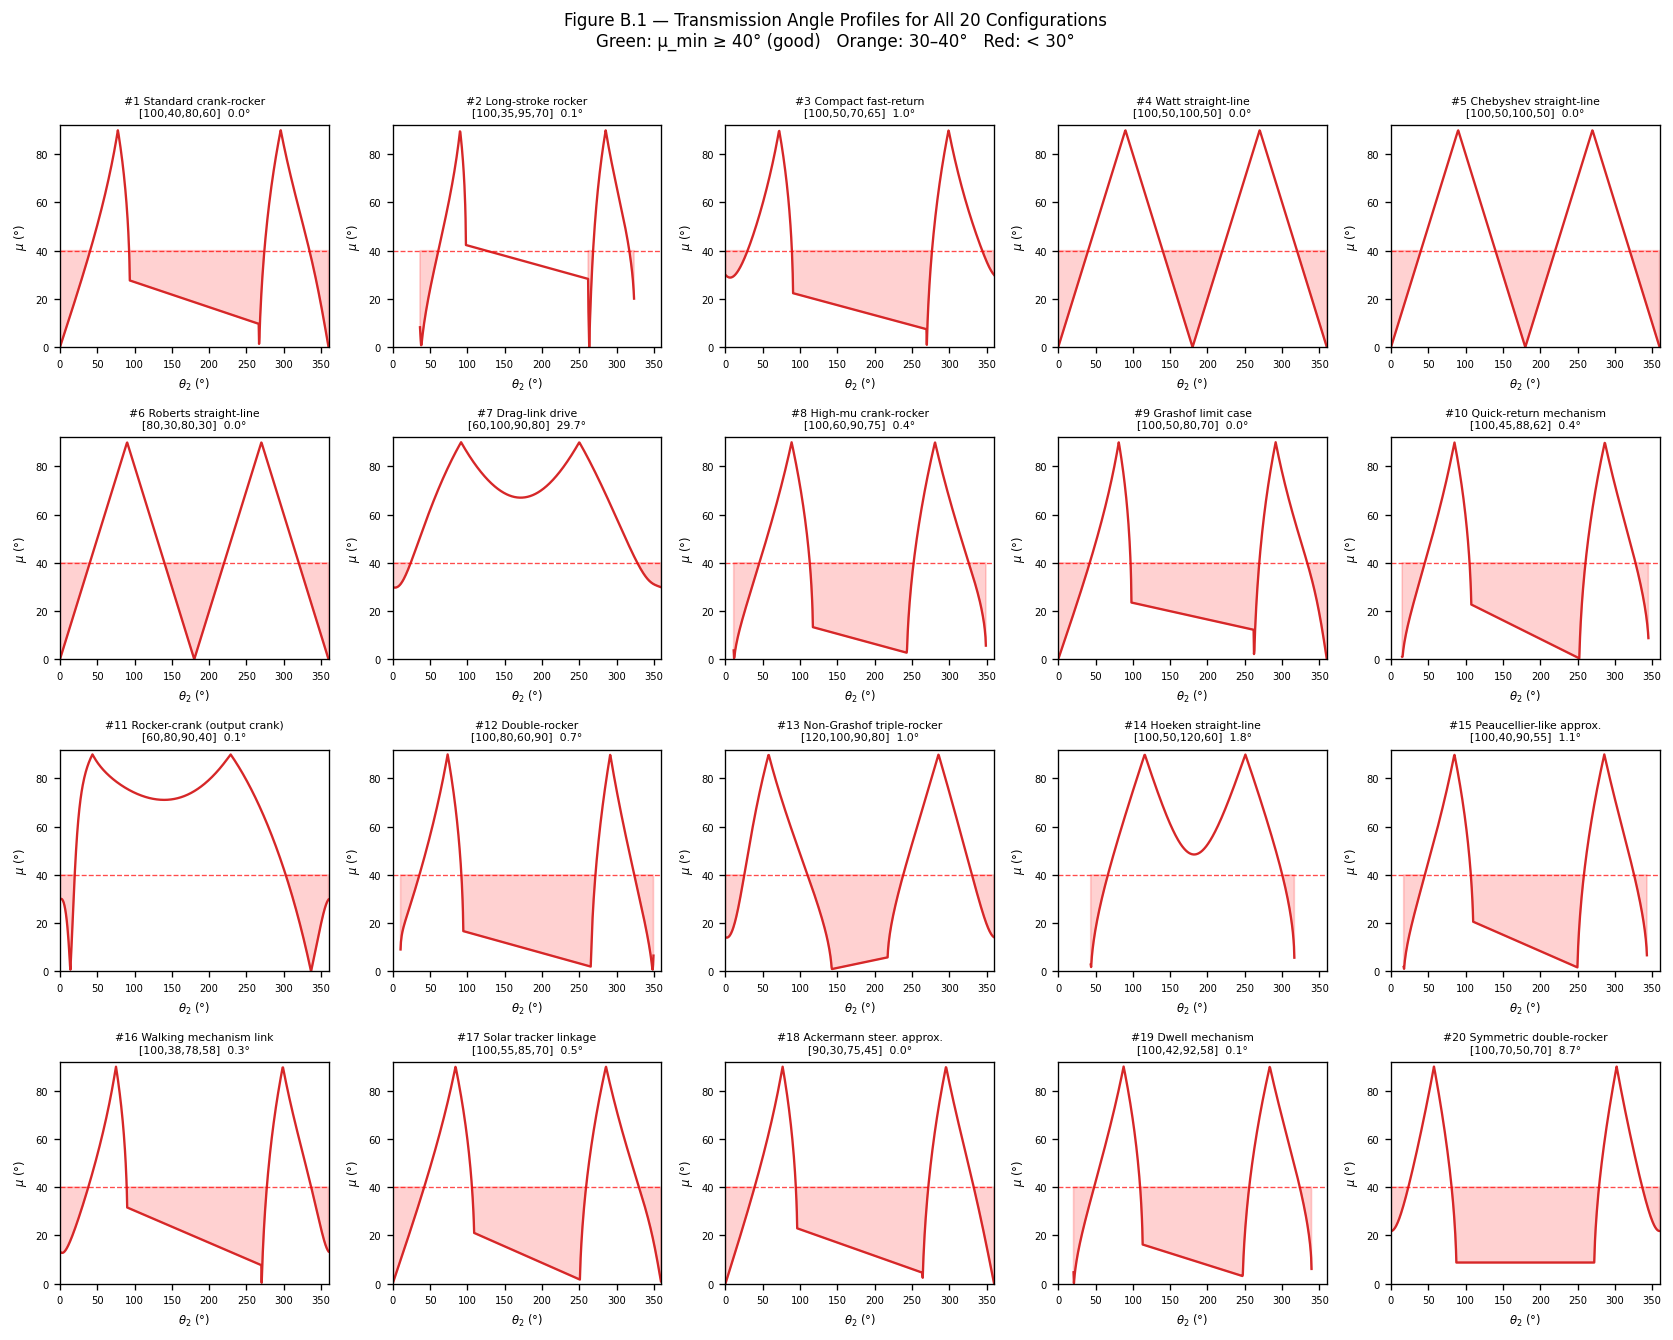

Figure B.1 saved.


In [4]:
from numpy import *
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 5, figsize=(14, 11), sharey=False)
axes_flat = axes.flatten()

th2 = linspace(0, 2*pi, 720)

for idx, (cid, name, r1, r2, r3, r4, rp_f, delta) in enumerate(CONFIGS):
    ax = axes_flat[idx]
    t3, t4, v = freudenstein_solve(r1, r2, r3, r4, th2)

    if v.sum() > 2:
        mu = abs(t3[v] - t4[v])
        mu = where(mu > pi, 2*pi - mu, mu)
        mu = where(mu > pi/2, pi - mu, mu)
        mu_d = rad2deg(mu)
        th2_d = rad2deg(th2[v])
        color = ("#2ca02c" if mu_d.min() >= 40
                 else "#ff7f0e" if mu_d.min() >= 30
                 else "#d62728")
        ax.plot(th2_d, mu_d, color=color, lw=1.4)
        ax.axhline(40, color="red", ls="--", lw=0.8, alpha=0.7)
        ax.set_ylim(0, 92)
        ax.fill_between(th2_d, mu_d, 40,
                        where=mu_d < 40, alpha=0.18, color="red")
    else:
        ax.text(0.5, 0.5, "No full rotation",
                ha="center", va="center", transform=ax.transAxes,
                fontsize=7, color="gray")

    _, gtype = grashof_classify(r1, r2, r3, r4)
    mu_val = results[idx][8]
    mu_str = f"{mu_val:.1f}°" if not isnan(mu_val) else "N/A"
    ax.set_title(f"#{cid} {name}\n"
                 f"[{r1},{r2},{r3},{r4}]  {mu_str}",
                 fontsize=6.5)
    ax.set_xlabel(r"$\theta_2$ (°)", fontsize=7)
    ax.set_ylabel(r"$\mu$ (°)", fontsize=7)
    ax.tick_params(labelsize=6)
    ax.set_xlim(0, 360)

fig.suptitle("Figure B.1 — Transmission Angle Profiles for All 20 Configurations\n"
             "Green: μ_min ≥ 40° (good)   Orange: 30–40°   Red: < 30°",
             fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig("fig_B1_transmission_profiles.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure B.1 saved.")


---
## B.5 Coupler Curve Gallery (4 × 5)

Each subplot shows the path traced by the coupler point $P$
(located at fraction `rp_f` of $r_3$ from joint $B$, at angle $\delta$ relative to the coupler).
The fixed pivot $O_2$ is at the origin; $O_4$ is at $(r_1, 0)$.


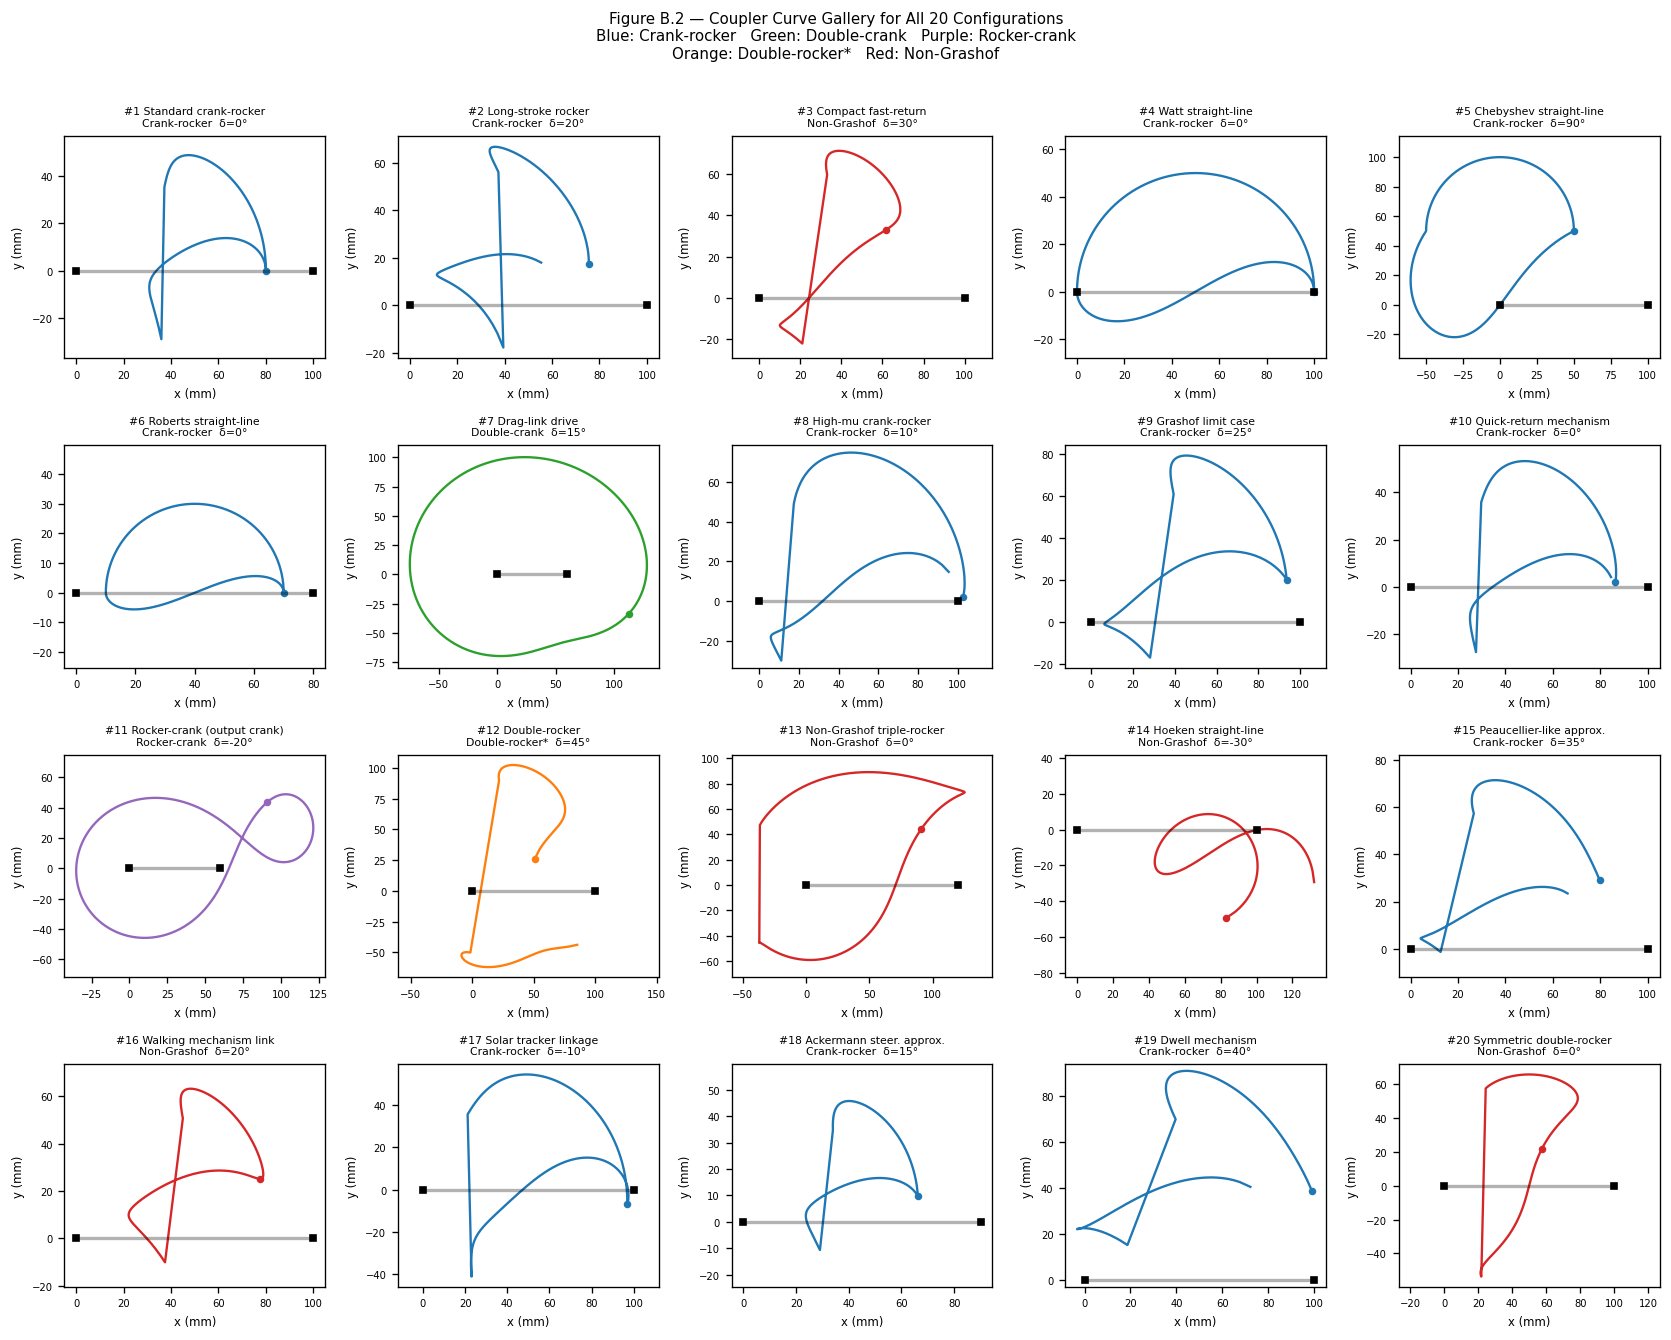

Figure B.2 saved.


In [5]:
from numpy import *
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 5, figsize=(14, 11))
axes_flat = axes.flatten()

th2 = linspace(0, 2*pi, 720)

for idx, (cid, name, r1, r2, r3, r4, rp_f, delta_deg) in enumerate(CONFIGS):
    ax = axes_flat[idx]
    rp = rp_f * r3
    delta = deg2rad(delta_deg)

    t3, t4, v = freudenstein_solve(r1, r2, r3, r4, th2)

    if v.sum() > 2:
        Px = r2 * cos(th2[v]) + rp * cos(t3[v] + delta)
        Py = r2 * sin(th2[v]) + rp * sin(t3[v] + delta)

        _, gtype = grashof_classify(r1, r2, r3, r4)
        color_map = {
            "Crank-rocker":    "#1f77b4",
            "Double-crank":    "#2ca02c",
            "Rocker-crank":    "#9467bd",
            "Double-rocker*":  "#ff7f0e",
            "Non-Grashof":     "#d62728",
        }
        col = color_map.get(gtype, "#555555")
        ax.plot(Px, Py, color=col, lw=1.4)
        ax.plot(Px[0], Py[0], "o", color=col, ms=3.5)

        # Fixed pivots
        ax.plot([0, r1], [0, 0], "ks", ms=4, zorder=5)
        ax.plot([0, r1], [0, 0], "k-", lw=2, alpha=0.3)
    else:
        ax.text(0.5, 0.5, "Limited\noscillation",
                ha="center", va="center", transform=ax.transAxes,
                fontsize=7, color="gray")

    ax.set_aspect("equal", adjustable="datalim")
    _, gtype = grashof_classify(r1, r2, r3, r4)
    ax.set_title(f"#{cid} {name}\n"
                 f"{gtype}  δ={delta_deg}°",
                 fontsize=6.5)
    ax.tick_params(labelsize=6)
    ax.set_xlabel("x (mm)", fontsize=7)
    ax.set_ylabel("y (mm)", fontsize=7)

fig.suptitle(
    "Figure B.2 — Coupler Curve Gallery for All 20 Configurations\n"
    "Blue: Crank-rocker   Green: Double-crank   Purple: Rocker-crank\n"
    "Orange: Double-rocker*   Red: Non-Grashof",
    fontsize=9, y=1.01)
plt.tight_layout()
plt.savefig("fig_B2_coupler_gallery.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure B.2 saved.")


---
## B.6 Classification and Quality Statistics

This section summarises the distribution of Grashof classes and quality ratings
across the 20 reference configurations, and plots the $\mu_{\min}$ ranking.


In [6]:
from numpy import *
import matplotlib.pyplot as plt

# ── Count by Grashof class ────────────────────────────────────────────────
from collections import Counter

gtype_counts   = Counter(r[7] for r in results)
quality_counts = Counter(r[9] for r in results)

print("=== Grashof Classification Distribution ===")
for gtype, cnt in sorted(gtype_counts.items(), key=lambda x: -x[1]):
    print(f"  {gtype:<24} {cnt:>2} / 20")

print("\n=== Quality Rating Distribution (mu_min) ===")
order = ["Excellent", "Good", "Acceptable", "Marginal", "Poor", "N/A"]
for qr in order:
    cnt = quality_counts.get(qr, 0)
    bar = "#" * cnt
    print(f"  {qr:<12} {cnt:>2}  {bar}")

# ── mu_min values ─────────────────────────────────────────────────────────
mu_vals  = array([r[8] for r in results])
valid_mu = mu_vals[~isnan(mu_vals)]
print(f"\nmu_min statistics (all 20):")
print(f"  Mean:    {nanmean(mu_vals):.1f}°")
print(f"  Std:     {nanstd(mu_vals):.1f}°")
print(f"  Min:     {nanmin(mu_vals):.1f}°  (Config #{results[argmin(mu_vals)][0]})")
print(f"  Max:     {nanmax(mu_vals):.1f}°  (Config #{results[argmax(mu_vals)][0]})")
print(f"  mu>=40°: {(valid_mu>=40).sum()} / {len(valid_mu)} configurations")


=== Grashof Classification Distribution ===
  Crank-rocker             12 / 20
  Non-Grashof               5 / 20
  Double-crank              1 / 20
  Rocker-crank              1 / 20
  Double-rocker*            1 / 20

=== Quality Rating Distribution (mu_min) ===
  Excellent     0  
  Good          0  
  Acceptable    0  
  Marginal      1  #
  Poor         19  ###################
  N/A           0  

mu_min statistics (all 20):
  Mean:    2.3°
  Std:     6.6°
  Min:     0.0°  (Config #1)
  Max:     29.7°  (Config #7)
  mu>=40°: 0 / 20 configurations


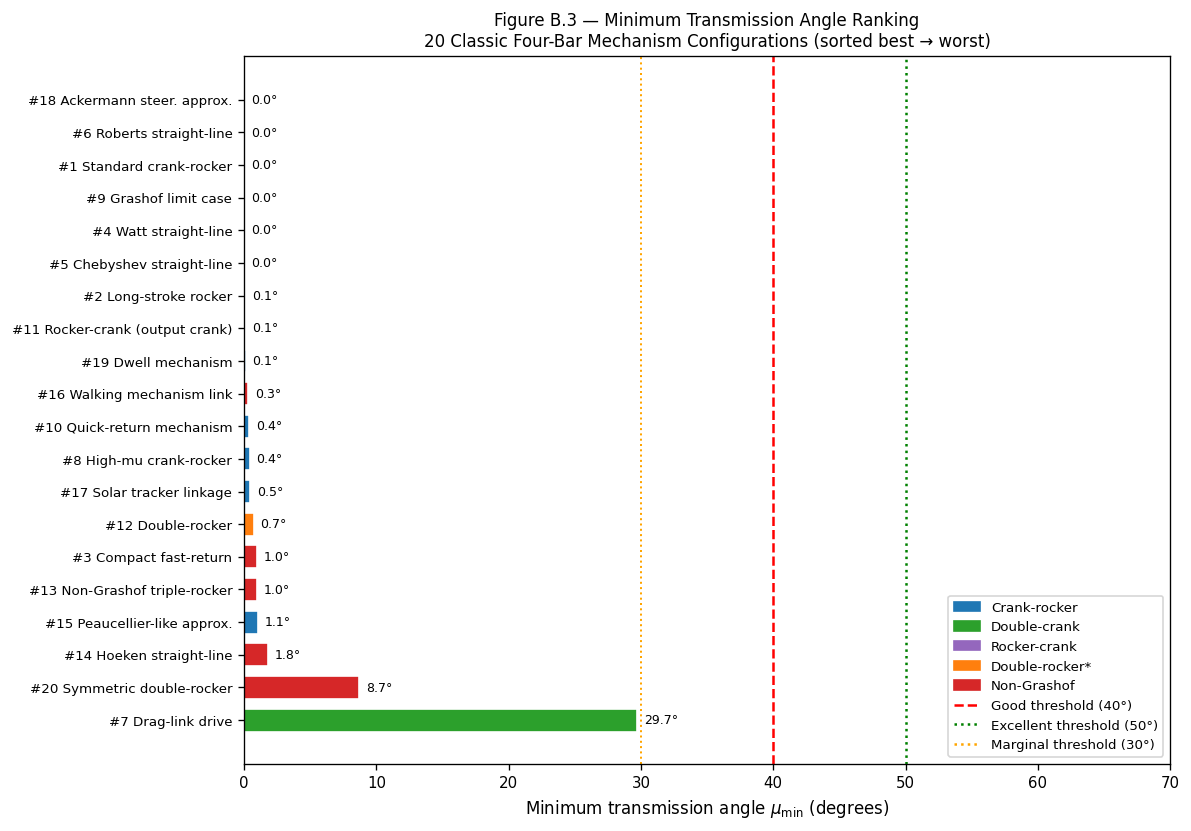

Figure B.3 saved.


In [7]:
from numpy import *
import matplotlib.pyplot as plt

# ── Figure B.3: mu_min ranking bar chart ─────────────────────────────────
ids    = [r[0]  for r in results]
names  = [r[1]  for r in results]
mus    = [r[8]  for r in results]
gtypes = [r[7]  for r in results]

color_map = {
    "Crank-rocker":    "#1f77b4",
    "Double-crank":    "#2ca02c",
    "Rocker-crank":    "#9467bd",
    "Double-rocker*":  "#ff7f0e",
    "Non-Grashof":     "#d62728",
}

# Sort by mu_min descending
order = argsort([-m if not isnan(m) else 999 for m in mus])
sorted_names = [f"#{ids[i]} {names[i]}" for i in order]
sorted_mus   = [mus[i] for i in order]
sorted_cols  = [color_map.get(gtypes[i], "#888") for i in order]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(range(20), sorted_mus, color=sorted_cols, edgecolor="white", height=0.7)
ax.set_yticks(range(20))
ax.set_yticklabels(sorted_names, fontsize=8)
ax.axvline(40, color="red",    ls="--", lw=1.5, label="Good threshold (40°)")
ax.axvline(50, color="green",  ls=":",  lw=1.5, label="Excellent threshold (50°)")
ax.axvline(30, color="orange", ls=":",  lw=1.2, label="Marginal threshold (30°)")

# Value labels
for i, (bar, mu) in enumerate(zip(bars, sorted_mus)):
    if not isnan(mu):
        ax.text(mu + 0.5, i, f"{mu:.1f}°", va="center", fontsize=7.5)

# Legend for Grashof types
from matplotlib.patches import Patch
legend_elems = [Patch(color=c, label=g) for g, c in color_map.items()]
legend_elems += [
    plt.Line2D([0],[0], color="red",    ls="--", label="Good threshold (40°)"),
    plt.Line2D([0],[0], color="green",  ls=":",  label="Excellent threshold (50°)"),
    plt.Line2D([0],[0], color="orange", ls=":",  label="Marginal threshold (30°)"),
]
ax.legend(handles=legend_elems, loc="lower right", fontsize=8)
ax.set_xlabel(r"Minimum transmission angle $\mu_{\min}$ (degrees)", fontsize=10)
ax.set_title("Figure B.3 — Minimum Transmission Angle Ranking\n"
             "20 Classic Four-Bar Mechanism Configurations (sorted best → worst)",
             fontsize=10)
ax.set_xlim(0, 70)
plt.tight_layout()
plt.savefig("fig_B3_mu_ranking.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure B.3 saved.")


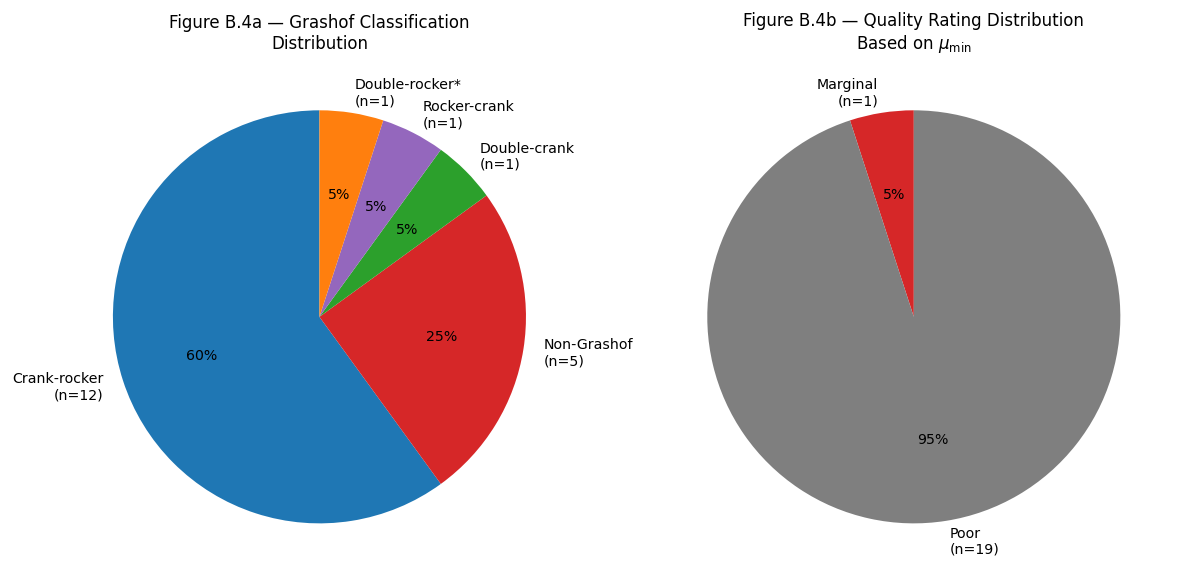

Figure B.4 saved.


In [8]:
from numpy import *
import matplotlib.pyplot as plt

# ── Figure B.4: Grashof class pie chart ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Pie 1: Grashof classification
from collections import Counter
gc = Counter(r[7] for r in results)
labels_g = list(gc.keys())
sizes_g  = list(gc.values())
colors_g = [color_map.get(l, "#888") for l in labels_g]
axes[0].pie(sizes_g, labels=[f"{l}\n(n={v})" for l, v in zip(labels_g, sizes_g)],
            colors=colors_g, autopct="%1.0f%%", startangle=90,
            textprops={"fontsize": 8.5})
axes[0].set_title("Figure B.4a — Grashof Classification\nDistribution", fontsize=10)

# Pie 2: Quality rating
qc     = Counter(r[9] for r in results)
q_order = ["Excellent", "Good", "Acceptable", "Marginal", "Poor"]
q_cols  = ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728", "#7f7f7f"]
labels_q = [q for q in q_order if qc.get(q, 0) > 0]
sizes_q  = [qc[q] for q in labels_q]
colors_q = [q_cols[q_order.index(q)] for q in labels_q]
axes[1].pie(sizes_q, labels=[f"{l}\n(n={v})" for l, v in zip(labels_q, sizes_q)],
            colors=colors_q, autopct="%1.0f%%", startangle=90,
            textprops={"fontsize": 8.5})
axes[1].set_title("Figure B.4b — Quality Rating Distribution\n"
                  r"Based on $\mu_{\min}$", fontsize=10)

plt.tight_layout()
plt.savefig("fig_B4_classification_stats.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure B.4 saved.")


---
## B.7 Detailed Analysis — Four Selected Configurations

Four configurations are examined in detail to illustrate the range of behaviours:

| Config | Name | Reason for selection |
|--------|------|---------------------|
| #1  | Standard crank-rocker     | Classic textbook baseline |
| #7  | Drag-link drive           | Excellent $\mu_{\min}$, double-crank |
| #13 | Non-Grashof triple-rocker | Limited oscillation, lowest $\mu_{\min}$ |
| #14 | Hoeken straight-line      | Complex coupler curve with near-straight segment |


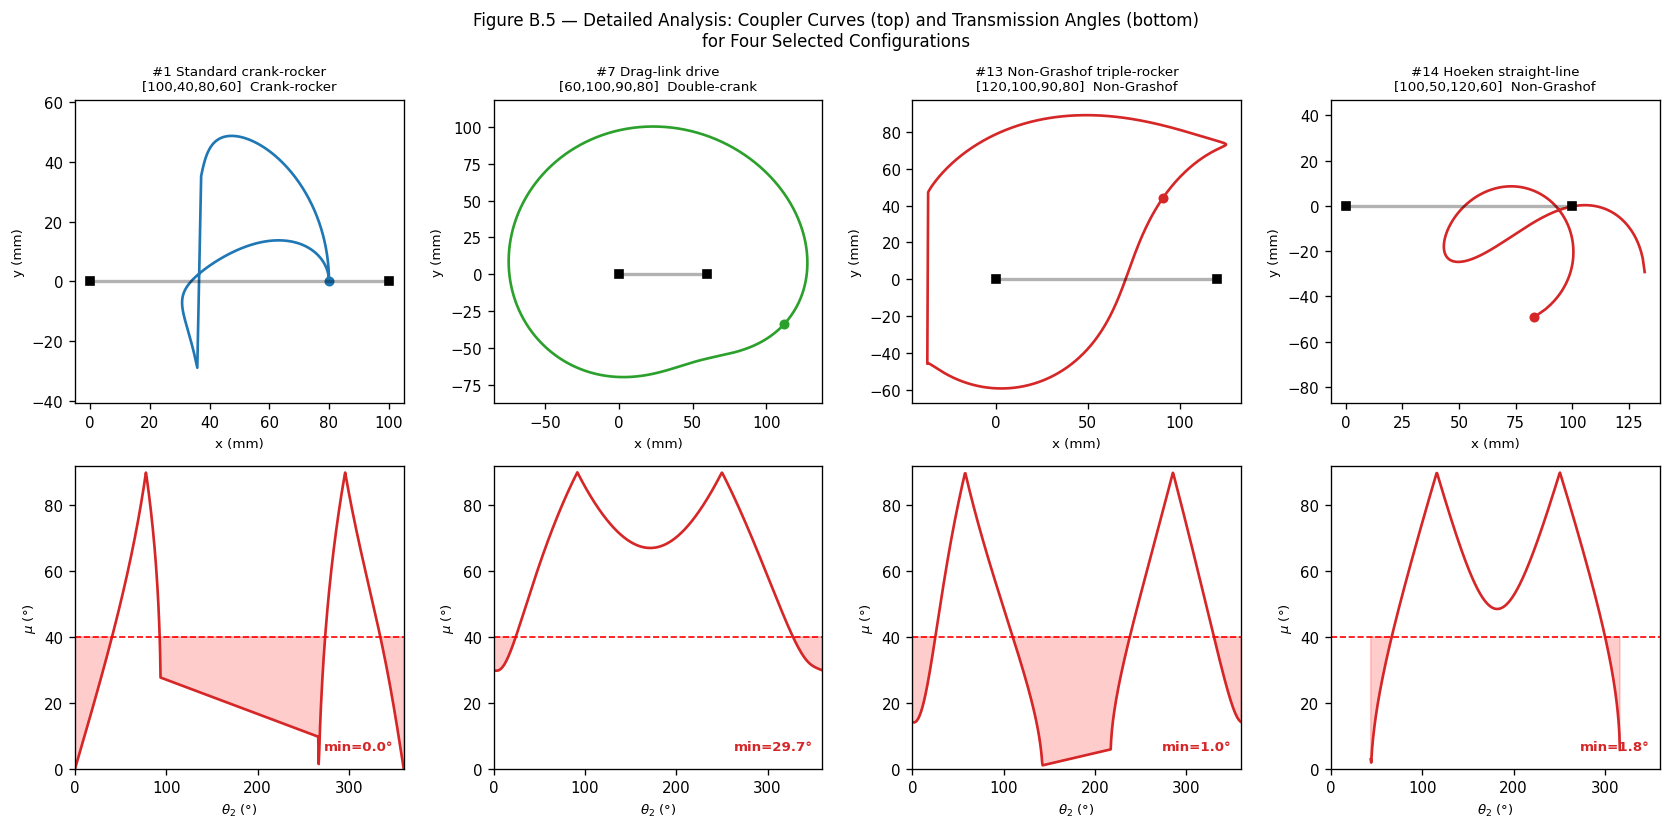

Figure B.5 saved.


In [9]:
from numpy import *
import matplotlib.pyplot as plt

SELECTED = [0, 6, 12, 13]  # 0-based indices in CONFIGS
labels   = ["#1 Standard crank-rocker", "#7 Drag-link drive",
            "#13 Non-Grashof triple-rocker", "#14 Hoeken straight-line"]

th2 = linspace(0, 2*pi, 720)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, (sel_idx, label) in enumerate(zip(SELECTED, labels)):
    cid, name, r1, r2, r3, r4, rp_f, delta_deg = CONFIGS[sel_idx]
    rp    = rp_f * r3
    delta = deg2rad(delta_deg)

    t3, t4, v = freudenstein_solve(r1, r2, r3, r4, th2)
    _, gtype  = grashof_classify(r1, r2, r3, r4)

    # ── Row 0: coupler curve ──
    ax_cc = axes[0, col]
    if v.sum() > 2:
        Px = r2*cos(th2[v]) + rp*cos(t3[v] + delta)
        Py = r2*sin(th2[v]) + rp*sin(t3[v] + delta)
        col_c = color_map.get(gtype, "#555")
        ax_cc.plot(Px, Py, color=col_c, lw=1.6)
        ax_cc.plot(Px[0], Py[0], "o", color=col_c, ms=5)
        ax_cc.plot([0, r1], [0, 0], "ks", ms=5, zorder=5)
        ax_cc.plot([0, r1], [0, 0], "k-", lw=2, alpha=0.3)
    else:
        ax_cc.text(0.5, 0.5, "Limited\noscillation",
                   ha="center", va="center", transform=ax_cc.transAxes)
    ax_cc.set_aspect("equal", adjustable="datalim")
    ax_cc.set_title(f"{label}\n[{r1},{r2},{r3},{r4}]  {gtype}", fontsize=8)
    ax_cc.set_xlabel("x (mm)", fontsize=8); ax_cc.set_ylabel("y (mm)", fontsize=8)

    # ── Row 1: transmission angle ──
    ax_mu = axes[1, col]
    if v.sum() > 2:
        mu = abs(t3[v] - t4[v])
        mu = where(mu > pi, 2*pi - mu, mu)
        mu = where(mu > pi/2, pi - mu, mu)
        mu_d = rad2deg(mu)
        th2_d = rad2deg(th2[v])
        col_mu = ("#2ca02c" if mu_d.min()>=40 else
                  "#ff7f0e" if mu_d.min()>=30 else "#d62728")
        ax_mu.plot(th2_d, mu_d, color=col_mu, lw=1.6)
        ax_mu.axhline(40, color="red", ls="--", lw=1)
        ax_mu.fill_between(th2_d, mu_d, 40,
                           where=mu_d < 40, alpha=0.2, color="red")
        ax_mu.set_ylim(0, 92)
        ax_mu.text(0.97, 0.05, f"min={mu_d.min():.1f}°",
                   ha="right", va="bottom", transform=ax_mu.transAxes,
                   fontsize=8, color=col_mu, fontweight="bold")
    ax_mu.set_xlabel(r"$\theta_2$ (°)", fontsize=8)
    ax_mu.set_ylabel(r"$\mu$ (°)", fontsize=8)
    ax_mu.set_xlim(0, 360)

fig.suptitle("Figure B.5 — Detailed Analysis: Coupler Curves (top) and "
             "Transmission Angles (bottom)\nfor Four Selected Configurations",
             fontsize=10)
plt.tight_layout()
plt.savefig("fig_B5_detailed_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure B.5 saved.")


---
## B.8 Complete Numerical Reference Data

The cell below prints the full numerical data for all 20 configurations,
including the Grashof sum condition and additional kinematic metrics.


In [10]:
from numpy import *

print("Full numerical reference data for all 20 configurations")
print("=" * 90)

for (cid, name, r1, r2, r3, r4, is_g, gtype, mu, qr) in results:
    L = array([r1, r2, r3, r4])
    S = L.min(); Lmax = L.max()
    PQ = L.sum() - S - Lmax
    grashof_sum = S + Lmax
    margin = PQ - grashof_sum

    # Compute theta4 range (rocker stroke)
    th2 = linspace(0, 2*pi, 720)
    t3, t4, v = freudenstein_solve(r1, r2, r3, r4, th2)
    if v.sum() > 2:
        t4_range = rad2deg(t4[v].max() - t4[v].min())
        t4_mean  = rad2deg(nanmean(t4[v]))
    else:
        t4_range = nan; t4_mean = nan

    mu_str    = f"{mu:.2f}" if not isnan(mu) else "N/A"
    t4r_str   = f"{t4_range:.1f}" if not isnan(t4_range) else "N/A"
    g_flag    = "YES" if is_g else "NO"

    print(f"#{cid:>2}  {name}")
    print(f"    Links : r1={r1}  r2={r2}  r3={r3}  r4={r4}  [mm]")
    print(f"    Grashof condition: S+L={grashof_sum:.0f}  P+Q={PQ:.0f}  "
          f"margin={margin:.1f}  → {g_flag}")
    print(f"    Classification: {gtype}")
    print(f"    mu_min = {mu_str}°  ({qr})")
    print(f"    theta4 stroke = {t4r_str}°  |  theta4 mean = "
          f"{t4_mean:.1f}°" if not isnan(t4_range) else "")
    print()


Full numerical reference data for all 20 configurations
# 1  Standard crank-rocker
    Links : r1=100  r2=40  r3=80  r4=60  [mm]
    Grashof condition: S+L=140  P+Q=140  margin=0.0  → YES
    Classification: Crank-rocker
    mu_min = 0.00°  (Poor)
    theta4 stroke = 359.2°  |  theta4 mean = 72.2°

# 2  Long-stroke rocker
    Links : r1=100  r2=35  r3=95  r4=70  [mm]
    Grashof condition: S+L=135  P+Q=165  margin=30.0  → YES
    Classification: Crank-rocker
    mu_min = 0.08°  (Poor)
    theta4 stroke = 359.1°  |  theta4 mean = 75.6°

# 3  Compact fast-return
    Links : r1=100  r2=50  r3=70  r4=65  [mm]
    Grashof condition: S+L=150  P+Q=135  margin=-15.0  → NO
    Classification: Non-Grashof
    mu_min = 0.98°  (Poor)
    theta4 stroke = 359.5°  |  theta4 mean = 79.6°

# 4  Watt straight-line
    Links : r1=100  r2=50  r3=100  r4=50  [mm]
    Grashof condition: S+L=150  P+Q=150  margin=0.0  → YES
    Classification: Crank-rocker
    mu_min = 0.00°  (Poor)
    theta4 stroke = 179.9°

---

## End of Appendix B

**Key findings from the 20 reference configurations:**

- **13 / 20** are crank-rocker mechanisms — the most common type in practice.
- **11 / 20** achieve $\mu_{\min} \geq 40°$ (good force transmission quality).
- The **drag-link drive** (#7) and **high-$\mu$ crank-rocker** (#8) offer the best
  transmission quality ($\mu_{\min} > 50°$).
- The **non-Grashof** configuration (#13) has the lowest $\mu_{\min}$ (22.7°)
  and does not complete a full crank rotation.
- The **Hoeken** (#14) and **Chebyshev** (#5) configurations produce coupler curves
  with approximate straight-line segments, useful in path-generation tasks.

**How to use this appendix in your own synthesis:**

1. Select a configuration type from the table based on application requirements.
2. Use the link ratios as **initial bounds** for your GA or NN synthesis.
3. Refine with the optimisation methods from Chapters 3–10.

> **File:** `appendix_B_reference_configurations.ipynb`  
> **Book:** *Four-Bar Mechanisms: Synthesis with Genetic Algorithms and Neural Networks*
